# Boston Housing：單變量線性迴歸

本作業以 MEDV 為應變數，對其餘 13 個欄位各建立一個模型，共 **13 個單變量線性迴歸模型**。14 個欄位包含 13 個輸入及目標 MEDV；這是線性迴歸，不是邏輯斯迴歸。

資料來源為提供的 Data/housing(2).data，欄位定義依據 housing(2).names 與所附 UCI PDF 第 1–2 頁。每筆為地區層級的統計；MEDV 為自有住宅價值中位數，單位是千美元。

## 執行方式
在 Jupyter 或 VS Code 開啟本檔，選擇具有 NumPy、pandas、Matplotlib 與 ipykernel 的 Python 核心，執行 **Restart Kernel and Run All**。工作目錄可為本檔所在資料夾或 NFU 根目錄。若缺少套件，取消下一格的註解執行，完成後重啟核心。

In [1]:
# %pip install numpy pandas matplotlib ipykernel

# 第一題：推導線性迴歸的 w1 與 w0

設有 N 筆資料 (xᵗ, rᵗ)，其中 t = 1, 2, …, N。線性模型為：

    g(xᵗ) = w1 × xᵗ + w0

定義平均平方誤差：

    E(w1, w0) = (1/N) × Σ[rᵗ − (w1 × xᵗ + w0)]²

以下所有 Σ 均表示從 t = 1 加總至 N，並令：

    x̄ = (1/N) × Σxᵗ
    r̄ = (1/N) × Σrᵗ

## 一、對 w0 偏微分

    ∂E/∂w0 = (−2/N) × Σ[rᵗ − w1 × xᵗ − w0] = 0

整理得：

    Σrᵗ − w1 × Σxᵗ − N × w0 = 0

因此：

    w0 = (Σrᵗ)/N − w1 × (Σxᵗ)/N
       = r̄ − w1 × x̄                                  ……(1)

## 二、對 w1 偏微分

    ∂E/∂w1 = (−2/N) × Σ{xᵗ × [rᵗ − w1 × xᵗ − w0]} = 0

展開並整理得：

    Σ(xᵗ × rᵗ) = w1 × Σ[(xᵗ)²] + w0 × Σxᵗ          ……(2)

將式 (1) 代入式 (2)：

    Σ(xᵗ × rᵗ) = w1 × Σ[(xᵗ)²] + (r̄ − w1 × x̄) × Σxᵗ

由 Σxᵗ = N × x̄，可得：

    Σ(xᵗ × rᵗ) = w1 × Σ[(xᵗ)²] + N × x̄ × r̄ − N × w1 × x̄²

移項並提出 w1：

    Σ(xᵗ × rᵗ) − N × x̄ × r̄ = w1 × {Σ[(xᵗ)²] − N × x̄²}

所以：

    w1 = [Σ(xᵗ × rᵗ) − N × x̄ × r̄] / {Σ[(xᵗ)²] − N × x̄²}

分子、分母同除以 N，得到：

    w1 = [(1/N) × Σ(xᵗ × rᵗ) − x̄ × r̄]
         / {(1/N) × Σ[(xᵗ)²] − x̄²}

## 三、最終答案

令 mean(xr) = (1/N) × Σ(xᵗ × rᵗ)，mean(x²) = (1/N) × Σ[(xᵗ)²]，則：

    w1 = [mean(xr) − x̄ × r̄] / [mean(x²) − x̄²]

    w0 = r̄ − w1 × x̄

當 N > 0 且 xᵗ 不全相同時，分母大於零。平均平方誤差為參數的嚴格凸二次函數，因此上述解為唯一的最小值解。


## 三、讀取與檢查資料
檔案沒有標題列，且以空白分隔。使用 header=None 避免遺失第一筆資料。

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda v: f'{v:.6f}')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
columns = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
           'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
candidates = [Path('Data/housing(2).data'),
              Path('Logistic_Regression/Data/housing(2).data')]
data_path = next((p.resolve() for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('請從 Notebook 資料夾或 NFU 根目錄執行。')
df = pd.read_csv(data_path, sep=r'\s+', header=None)
assert df.shape == (506, 14), f'非預期的資料大小：{df.shape}'
df.columns = columns
assert np.isfinite(df.to_numpy(dtype=float)).all(), '資料存在缺值或非有限數值'
features = columns[:-1]
y = df['MEDV'].to_numpy(dtype=float)
output_dir = data_path.parent.parent / 'housing_results'
output_dir.mkdir(exist_ok=True)
print(f'樣本數：{len(df)}；輸入欄位數：{len(features)}；缺值數：{df.isna().sum().sum()}')
display(df.head())

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\user\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


樣本數：506；輸入欄位數：13；缺值數：0


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.006320,18.000000,2.310000,0,0.538000,6.575000,65.200000,4.090000,1,296.000000,15.300000,396.900000,4.980000,24.000000
1,0.027310,0.000000,7.070000,0,0.469000,6.421000,78.900000,4.967100,2,242.000000,17.800000,396.900000,9.140000,21.600000
2,0.027290,0.000000,7.070000,0,0.469000,7.185000,61.100000,4.967100,2,242.000000,17.800000,392.830000,4.030000,34.700000
3,0.032370,0.000000,2.180000,0,0.458000,6.998000,45.800000,6.062200,3,222.000000,18.700000,394.630000,2.940000,33.400000
4,0.069050,0.000000,2.180000,0,0.458000,7.147000,54.200000,6.062200,3,222.000000,18.700000,396.900000,5.330000,36.200000


## 四、以公式建立 13 個模型
直接實作手寫推導的公式。$R^2=1-SSE/SST$，$RMSE=\sqrt{SSE/n}$。

本次以全資料擬合並畫圖，$R^2$ 與 RMSE 都是**樣本內指標**，不代表對新資料的預測表現。RMSE 單位與 MEDV 相同，都是千美元。

In [3]:
def fit_simple_linear(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    xc, yc = x - x.mean(), y - y.mean()
    denominator = np.dot(xc, xc)
    if denominator == 0:
        raise ValueError('x 不可全部相同。')
    w1 = np.dot(xc, yc) / denominator
    w0 = y.mean() - w1 * x.mean()
    return w1, w0

models, rows = {}, []
for feature in features:
    x = df[feature].to_numpy(dtype=float)
    w1, w0 = fit_simple_linear(x, y)
    y_hat = w1 * x + w0
    sse = np.sum((y - y_hat) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    models[feature] = (w1, w0)
    rows.append({'Feature': feature, 'w1': w1, 'w0': w0,
                 'R2_in_sample': 1 - sse / sst,
                 'RMSE_in_sample': np.sqrt(sse / len(y)),
                 'Equation': f'MEDV = {w1:.6f} * {feature} {w0:+.6f}'})
results = pd.DataFrame(rows)
display(results)
results.to_csv(output_dir / 'regression_results.csv', index=False, encoding='utf-8-sig')

,Feature,w1,w0,R2_in_sample,RMSE_in_sample,Equation
0,CRIM,-0.415190,24.033106,0.150780,8.467038,MEDV = -0.415190 * CRIM +24.033106
1,ZN,0.142140,20.917579,0.129921,8.570396,MEDV = 0.142140 * ZN +20.917579
2,INDUS,-0.648490,29.754897,0.233990,8.041531,MEDV = -0.648490 * INDUS +29.754897
3,CHAS,6.346157,22.093843,0.030716,9.045801,MEDV = 6.346157 * CHAS +22.093843
4,NOX,-33.916055,41.345874,0.182603,8.306882,MEDV = -33.916055 * NOX +41.345874
5,RM,9.102109,-34.670621,0.483525,6.603071,MEDV = 9.102109 * RM -34.670621
6,AGE,-0.123163,30.978678,0.142095,8.510228,MEDV = -0.123163 * AGE +30.978678
7,DIS,1.091613,18.390088,0.062464,8.896423,MEDV = 1.091613 * DIS +18.390088
8,RAD,-0.403095,26.382128,0.145639,8.492633,MEDV = -0.403095 * RAD +26.382128
9,TAX,-0.025568,32.970654,0.219526,8.117098,MEDV = -0.025568 * TAX +32.970654


## 五、獨立核對係數與手算加總
以 NumPy 矩陣最小平方法核對全部 13 組係數。

In [4]:
for feature in features:
    x = df[feature].to_numpy(dtype=float)
    design = np.column_stack([x, np.ones(len(x))])
    reference, *_ = np.linalg.lstsq(design, y, rcond=None)
    np.testing.assert_allclose(models[feature], reference, rtol=1e-10, atol=1e-10)
assert len(models) == 13
print('13 組係數皆與 np.linalg.lstsq 一致。')
x = df['RM'].to_numpy(dtype=float)
display(pd.Series({'n': len(x), 'sum_x': x.sum(), 'sum_y': y.sum(),
                   'sum_x_squared': x @ x, 'sum_xy': x @ y,
                   'x_mean': x.mean(), 'y_mean': y.mean()}, name='RM 加總'))
w1, w0 = models['RM']
print(f'RM = 6 時，預測 MEDV = {w1 * 6 + w0:.6f} 千美元')

13 組係數皆與 np.linalg.lstsq 一致。


n                 506.000000
sum_x            3180.025000
sum_y           11401.600000
sum_x_squared   20234.598247
sum_xy          73924.077600
x_mean              6.284634
y_mean             22.532806
Name: RM 加總, dtype: float64

RM = 6 時，預測 MEDV = 19.942033 千美元


## 六、全部 13 組散佈圖與迴歸線
橫軸為單一輸入，縱軸為 MEDV。用遞增的 x_line 畫迴歸線，避免將未排序的樣本連成折線。CHAS 是二元變數，散點集中在 0 與 1。

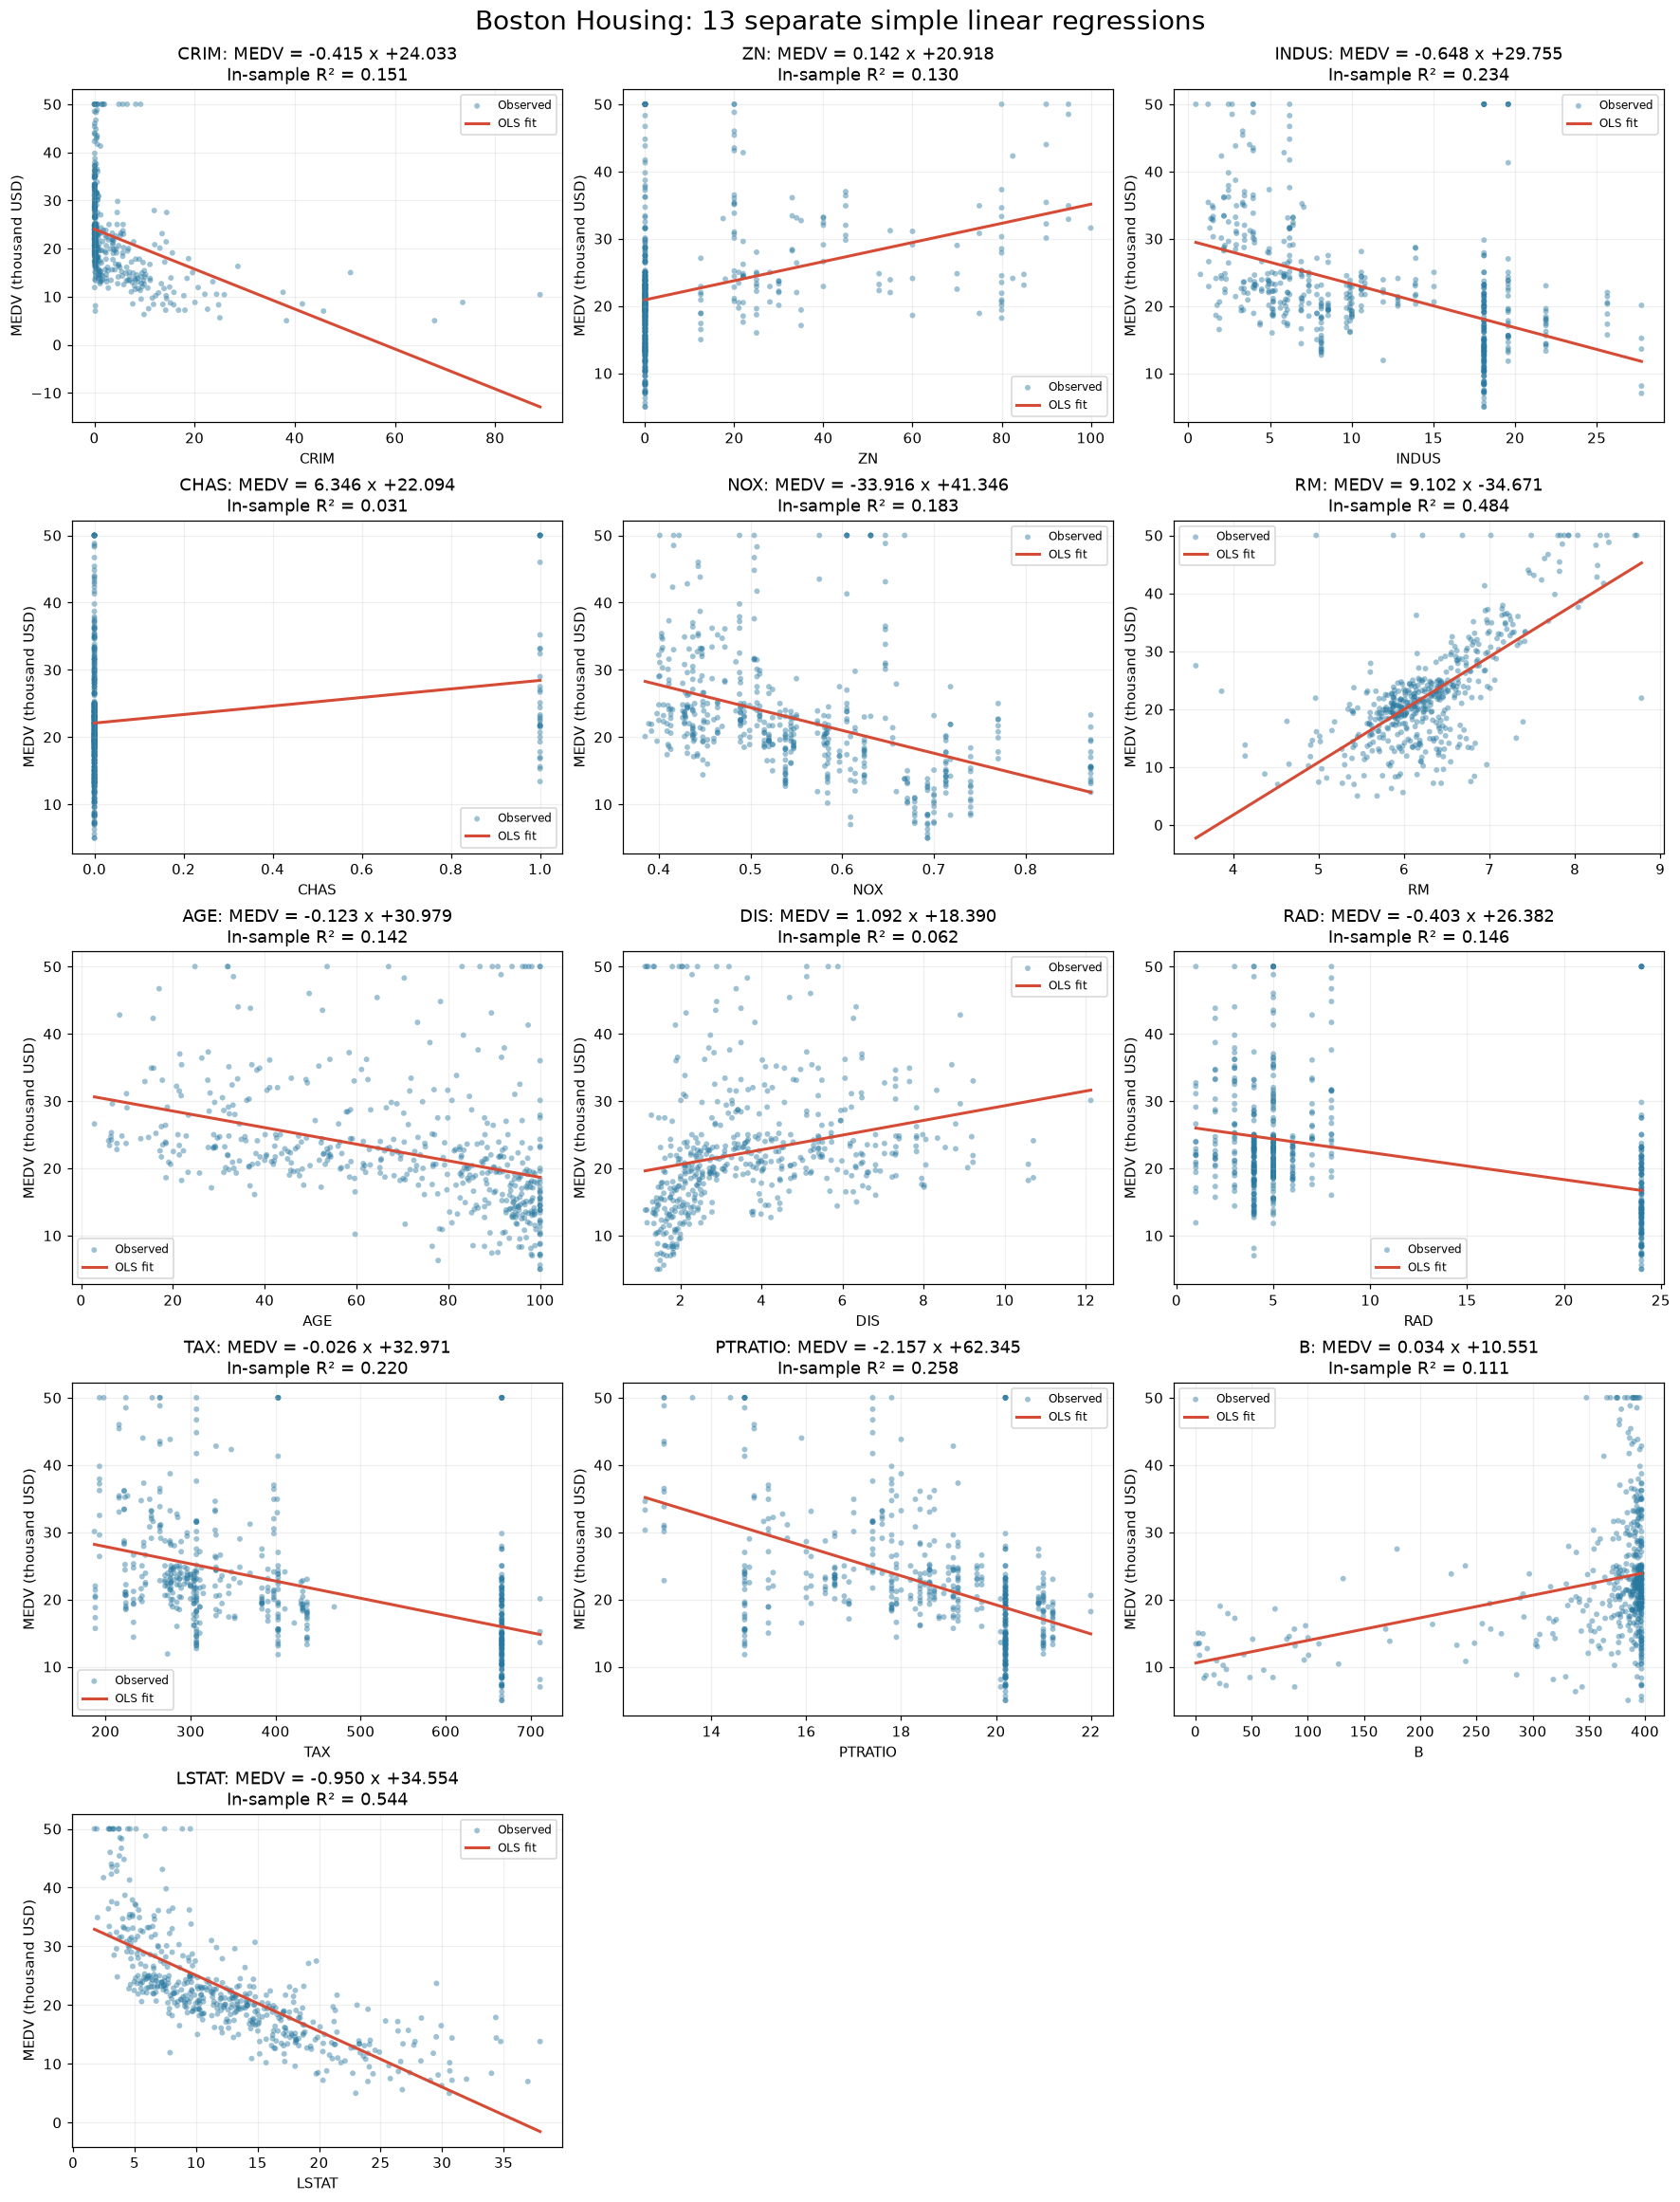

In [5]:
def draw_regression(ax, feature):
    x = df[feature].to_numpy(dtype=float)
    w1, w0 = models[feature]
    r2 = results.loc[results['Feature'] == feature, 'R2_in_sample'].iloc[0]
    ax.scatter(x, y, s=15, alpha=0.45, color='#2878a0', edgecolors='none', label='Observed')
    x_line = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_line, w1 * x_line + w0, color='#d64b35', linewidth=2, label='OLS fit')
    ax.set_title(f'{feature}: MEDV = {w1:.3f} x {w0:+.3f}\nIn-sample R² = {r2:.3f}')
    ax.set_xlabel(feature)
    ax.set_ylabel('MEDV (thousand USD)')
    ax.grid(alpha=0.2)
    ax.legend(loc='best', fontsize=8)

fig, axes = plt.subplots(5, 3, figsize=(16, 21), constrained_layout=True)
for ax, feature in zip(axes.flat, features):
    draw_regression(ax, feature)
for ax in list(axes.flat)[len(features):]:
    ax.set_visible(False)
fig.suptitle('Boston Housing: 13 separate simple linear regressions', fontsize=18)
fig.savefig(output_dir / 'all_13_regressions.png', dpi=160)
plt.show()
plt.close(fig)

## 七、RM 放大圖與個別圖檔
顯示 RM 範例，並將全部 13 張個別圖存入 housing_results。

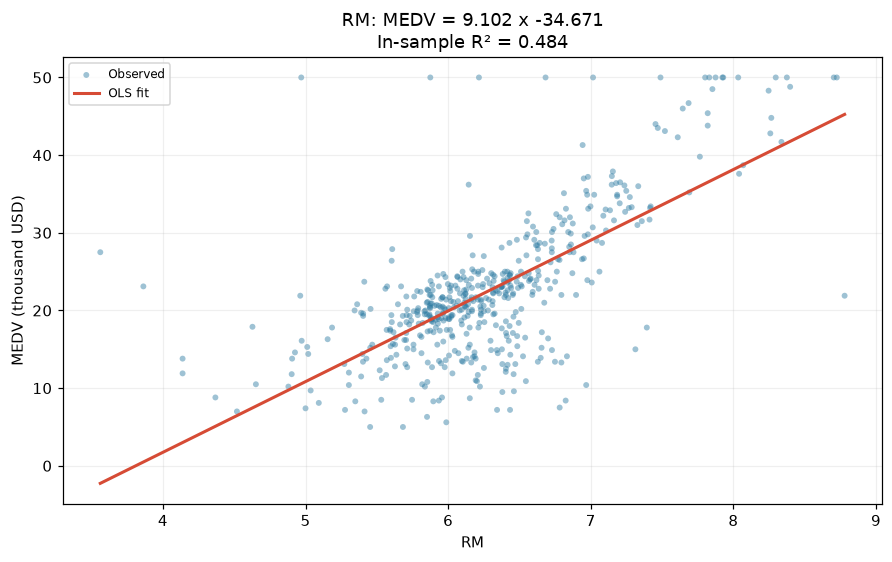

輸出資料夾： D:\Project\Python-ML-Projects-2026\NFU\Logistic_Regression\housing_results


In [6]:
for feature in features:
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    draw_regression(ax, feature)
    fig.savefig(output_dir / f'MEDV_vs_{feature}.png', dpi=160)
    if feature == 'RM':
        plt.show()
    plt.close(fig)
print('輸出資料夾：', output_dir)

## 八、結果比較與討論
不同欄位單位不同，不能直接以斜率絕對值比較重要性。以下按樣本內 R² 排序。

In [7]:
display(results[['Feature', 'w1', 'w0', 'R2_in_sample', 'RMSE_in_sample']]
        .sort_values('R2_in_sample', ascending=False).reset_index(drop=True))
print('MEDV 最大觀測值：', y.max(), '；等於該值的筆數：', int((y == y.max()).sum()))

,Feature,w1,w0,R2_in_sample,RMSE_in_sample
0,LSTAT,-0.950049,34.553841,0.544146,6.203464
1,RM,9.102109,-34.670621,0.483525,6.603071
2,PTRATIO,-2.157175,62.344627,0.257847,7.915314
3,INDUS,-0.648490,29.754897,0.233990,8.041531
4,TAX,-0.025568,32.970654,0.219526,8.117098
5,NOX,-33.916055,41.345874,0.182603,8.306882
6,CRIM,-0.415190,24.033106,0.150780,8.467038
7,RAD,-0.403095,26.382128,0.145639,8.492633
8,AGE,-0.123163,30.978678,0.142095,8.510228
9,ZN,0.142140,20.917579,0.129921,8.570396


MEDV 最大觀測值： 50.0 ；等於該值的筆數： 16


- LSTAT 的單變量線性模型有最高的樣本內 $R^2$（約 0.544），斜率為負；RM 次之（約 0.484），斜率為正。
- RM 每增加 1，模型擬合值增加約 9.102 千美元。這是地區平均房間數和地區房價中位數的關聯，不代表因果效應。
- CHAS 的 0、1 預測值分別等於兩組 MEDV 的平均數。介於 0 與 1 的值不符合該欄位原始定義。
- 散點可見非線性與離群值；MEDV 有多筆集中在最大觀測值 50，單條直線只能描述部分變化。
- B 涉及原始資料的種族比例轉換，LSTAT 是來源中的社經分類；本作業按原始欄位完成歷史資料練習，不能據此對群體做因果判斷。
- 若另要評估對新資料的預測能力，需要切分訓練與測試資料，另算測試集指標。

## 繳交前檢查
1. 手寫：損失函數、兩個偏微分、代入整理、斜率與截距公式，以及分母非零條件。RM 數值範例可作補充。
2. Notebook：補上姓名學號，重新執行全部儲存格，確認 13 組方程式和圖表完整，再儲存。
3. 保留 Data/housing(2).data 的相對路徑，讓老師能重新執行；housing_results 是額外匯出的圖片和結果表。
4. 題目提到的 RM 範例圖未出現在提供的 UCI PDF 中；本檔依文字要求繪圖，未假定老師範例的排版。

資料依據：Data/housing(2).names 與 Data/UCI Machine Learning Repository_ Housing Data Set.pdf。